In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import os

dir=os.path.join(os.getcwd(),'..','data')
df=pd.read_csv(os.path.join(dir,'train.csv'))


In [3]:
#Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,hasCabin,Embarked

#Survived and pclass --> cat and cat 2,3 chi square independence test 
# survived and sex cat and cat 2 and 2 --- 2 sample proportion test 
# Sruvived and Age cat and cont = 2 sample mean test 
# survived and fare cat and cont =2 sample mean test 
# survived and hasCabin cat and cat 2 sample proportional test 
#survived and Embarked cat and cat 2 , 3 chi square test
#  #

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB
None
hasCabin
0  

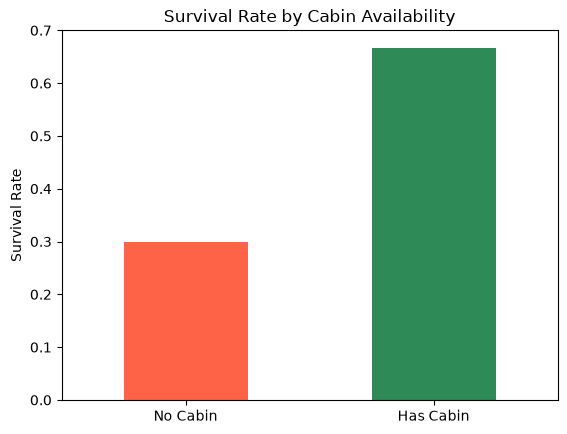

Pclass
1    0.814815
2    0.086957
3    0.024440
Name: hasCabin, dtype: float64


In [4]:
#-----------------------------------Completeness---------------------------------
print(df.isna().sum())
print(df.info()) #most capin is nan so i



#relationship between cabin and surviving

# df['hasCabin']=df['Cabin'].na.astype(int)



# 1) عمود يوضح هل الراكب عنده كابينة ولا لأ
df['hasCabin'] = df['Cabin'].notna().astype(int)

# 2) نسبة النجاة لكل مجموعة
survival_rate = df.groupby('hasCabin')['Survived'].mean()
print(survival_rate)

# 3) الرسم
survival_rate.index = ['No Cabin', 'Has Cabin']
survival_rate.plot(kind='bar', color=['tomato', 'seagreen'])
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Cabin Availability')
plt.xticks(rotation=0)
plt.show()



relation_between_Pclass_and_cabin=df.groupby("Pclass")['hasCabin'].mean()  #is that reducndant information

print(relation_between_Pclass_and_cabin)



Chi2ContingencyResult(statistic=np.float64(557.3102629401849), pvalue=np.float64(9.585484042103076e-122), dof=2, expected_freq=array([[166.54545455, 141.87205387, 378.58249158],
       [ 49.45454545,  42.12794613, 112.41750842]]))


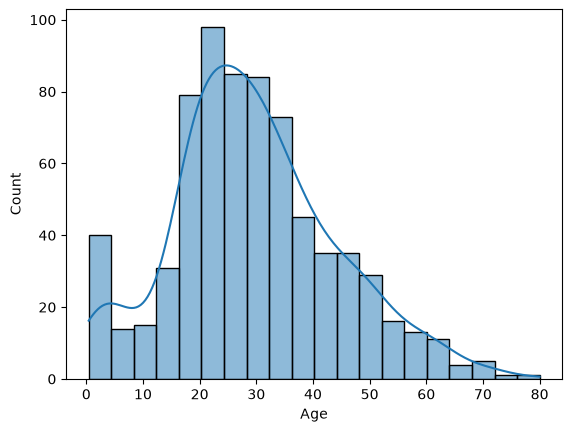

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
hasCabin         0
dtype: int64


In [5]:
#2 cat 1-2 1-3 means chi2 test
contingencyTable=pd.crosstab(df["hasCabin"],df["Pclass"])
chi2_cabin_pclass=stats.chi2_contingency(contingencyTable)
print(chi2_cabin_pclass)
# Chi2ContingencyResult(statistic=np.float64(238.40460966993172), pvalue=np.float64(1.7025378668863945e-52), dof=2, expected_freq=array([[ 83.70574163,  72.75358852, 170.54066986],
#        [ 23.29425837,  20.24641148,  47.45933014]]))

#there is signigicant relationship between Cabin and Pclass


# df=df.drop(["Cabin"],axis=1)
# df.drop(152,inplace=True)

sns.histplot(df['Age'],kde=True) #right skewed use median instead of mean

plt.show()

df['Age']=df['Age'].fillna(df['Age'].median())
print(df.isna().sum())


In [6]:
print(df[df['Fare'].isna()]) # index 152


Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked, hasCabin]
Index: []


In [7]:
df['Sex']=(df['Sex']=="female").astype(int)

df=df.drop(["Name","PassengerId"],axis=1)  #not important

print(df.info())
print(df['Ticket'].unique())
print(df["Embarked"].unique())
# sns.heatmap(df.corr(),annot=True)
# plt.show()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    int64  
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Ticket    891 non-null    str    
 7   Fare      891 non-null    float64
 8   Cabin     204 non-null    str    
 9   Embarked  889 non-null    str    
 10  hasCabin  891 non-null    int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 84.4 KB
None
<ArrowStringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C.A./SOTON 34068',  'SOT

In [8]:
#Survived,Pclass,Name,Sex,Age,SibSp,Parch -->parets ,Ticket,Fare,hasCabin,Embarked

#Survived and pclass --> cat and cat 2,3 chi square independence test 
# survived and sex cat and cat 2 and 2 --- 2 sample proportion test 
# Sruvived and Age cat and cont = 2 sample mean test 
# survived and fare cat and cont =2 sample mean test 
# survived and hasCabin cat and cat 2 sample proportional test 
#survived and Embarked cat and cat 2 , 3 chi square test
#  #

# Pclass1_survived=df[df['PassengerId']==1]['Survived']

# Pclass2_survived=df[df['PassengerId']==2]['Survived']
# Pclass3_survived=df[df['PassengerId']==3]['Survived']

#-----------------------Pclass and survive-----------------------------
contingencyTable_Pclass_survived=pd.crosstab(df['Pclass'],df['Survived'])
p_value_Pclass_Survived=stats.chi2_contingency(contingencyTable_Pclass_survived)
print(p_value_Pclass_Survived)#pvalue=np.float64(0.03519206276590605)
#there is significant relaitonShip


Chi2ContingencyResult(statistic=np.float64(102.88898875696056), pvalue=np.float64(4.549251711298793e-23), dof=2, expected_freq=array([[133.09090909,  82.90909091],
       [113.37373737,  70.62626263],
       [302.53535354, 188.46464646]]))


In [9]:
#----------------------- Sex and survive-----------------------------

# male_survive=df[df["Sex"]=="male"]["Survived"]
# female_survive=df[df['Sex']=="female"]['Survived']
contingencyTable_sex_survived=pd.crosstab(df['Sex'],df['Survived'])
p_value_sex_Survived=stats.chi2_contingency(contingencyTable_sex_survived)
print(p_value_sex_Survived)
# pvalue=np.float64(5.767311139789629e-92) --->there is signigicant relationship

Chi2ContingencyResult(statistic=np.float64(260.71702016732104), pvalue=np.float64(1.1973570627755645e-58), dof=1, expected_freq=array([[355.52525253, 221.47474747],
       [193.47474747, 120.52525253]]))


In [10]:
#-----------------------Sruvived and Age-----------------------------


survived_age=df[df["Survived"]==1]['Age']
unsurvived_age=df[df['Survived']==0]['Age']
pvalue_age_survived=stats.ttest_ind(survived_age,unsurvived_age, equal_var=False,nan_policy='omit')
print(pvalue_age_survived) #pvalue=np.float64(0.999822366421643) 
#no significant relationship

TtestResult(statistic=np.float64(-1.8966053920256696), pvalue=np.float64(0.0583091599777575), df=np.float64(671.1541729069276))


In [11]:

#-----------------------Sruvived and fare-----------------------------

survived_fare=df[df['Survived']==1]['Fare']
unservivied_fare=df[df['Survived']==0]['Fare']
Pvalue_fare_survived=stats.ttest_ind(survived_fare,unservivied_fare,nan_policy="omit",equal_var=False)
print(Pvalue_fare_survived) # pvalue=np.float64(0.0006845156351814136)

#there is significant relationship

TtestResult(statistic=np.float64(6.839099259085254), pvalue=np.float64(2.6993323503141203e-11), df=np.float64(436.7022760386057))


In [12]:
#-------------------# survived and hasCabin------------------------------
df['hasCabin']=df['Cabin'].notna().astype(int)
contingencyTable_survived_hasCabin=pd.crosstab(df['Survived'],df['hasCabin'])
pvalue_hasCabin_survived=stats.chi2_contingency(contingencyTable_survived_hasCabin)
print(pvalue_hasCabin_survived) # pvalue=np.float64(0.010329410353069566)
#there is significant relationship


Chi2ContingencyResult(statistic=np.float64(87.94148561238097), pvalue=np.float64(6.7419704360811776e-21), dof=1, expected_freq=array([[423.3030303, 125.6969697],
       [263.6969697,  78.3030303]]))


In [13]:


#-------------------# survived and Embarked------------------------------

#cat and cat chi2
# print(df['Embarked'].unique())
# Q_survived=df[df['Embarked']=='Q']['Survived']
# S_survived=df[df['Embarked']=='S']['Survived']
# C_survived=df[df['Embarked']=='C']['Survived']

contingencyTable_survived_Embarked=pd.crosstab(df['Survived'],df['Embarked'])
p_valude_emabarked_survive=stats.chi2_contingency(contingencyTable_survived_Embarked)
print(p_valude_emabarked_survive) #  pvalue=np.float64(0.03039815424608473) 
#there is significant relationship

#-------------------survived and SibSp------------------------------
contingencyTable_survived_sipsb=pd.crosstab(df['Survived'],df['SibSp'])
p_valude_SibSp_survive=stats.chi2_contingency(contingencyTable_survived_sipsb)
print(p_valude_SibSp_survive) #pvalue=np.float64(0.033092313600883064)
#there is significant relationship

#-------------------# survived and parch------------------------------
contingencyTable_survived_parch=pd.crosstab(df['Survived'],df['Parch'])
Pvalue_parch_survive=stats.chi2_contingency(contingencyTable_survived_parch)
print(Pvalue_parch_survive)# pvalue=np.float64(0.0005106898057600887)
#there is significant relationship

#drop Ticket , name,PassengerId and try without age

Chi2ContingencyResult(statistic=np.float64(26.48914983923762), pvalue=np.float64(1.769922284120912e-06), dof=2, expected_freq=array([[103.7480315,  47.5511811, 397.7007874],
       [ 64.2519685,  29.4488189, 246.2992126]]))
Chi2ContingencyResult(statistic=np.float64(37.27179291520431), pvalue=np.float64(1.5585810465902116e-06), dof=6, expected_freq=array([[374.62626263, 128.77777778,  17.25252525,   9.85858586,
         11.09090909,   3.08080808,   4.31313131],
       [233.37373737,  80.22222222,  10.74747475,   6.14141414,
          6.90909091,   1.91919192,   2.68686869]]))
Chi2ContingencyResult(statistic=np.float64(27.925784060236168), pvalue=np.float64(9.703526421039997e-05), dof=6, expected_freq=array([[4.17757576e+02, 7.27070707e+01, 4.92929293e+01, 3.08080808e+00,
        2.46464646e+00, 3.08080808e+00, 6.16161616e-01],
       [2.60242424e+02, 4.52929293e+01, 3.07070707e+01, 1.91919192e+00,
        1.53535354e+00, 1.91919192e+00, 3.83838384e-01]]))


<Axes: xlabel='Fare', ylabel='Count'>

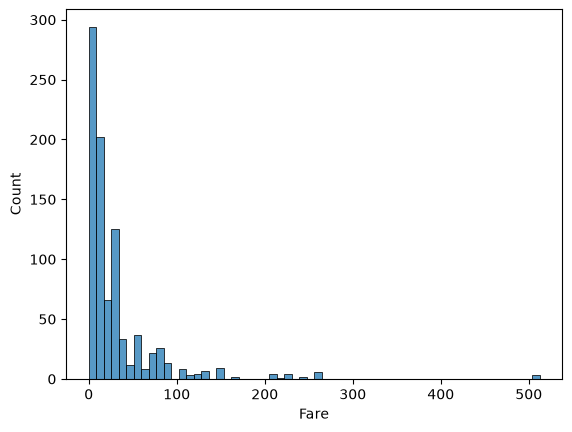

In [14]:
sns.histplot(df['Fare'])


<Axes: xlabel='Age', ylabel='Count'>

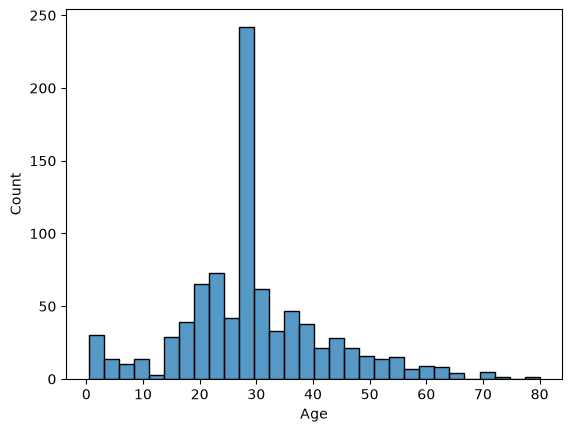

In [15]:
sns.histplot(df['Age'])


<Axes: xlabel='Fare', ylabel='Count'>

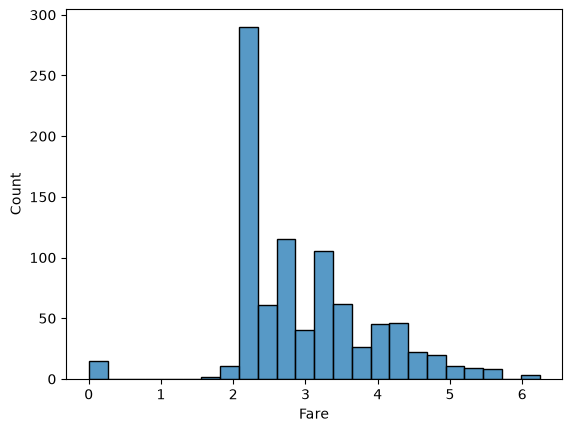

In [16]:
sns.histplot(np.log1p(df['Fare']))

<Axes: xlabel='Age', ylabel='Count'>

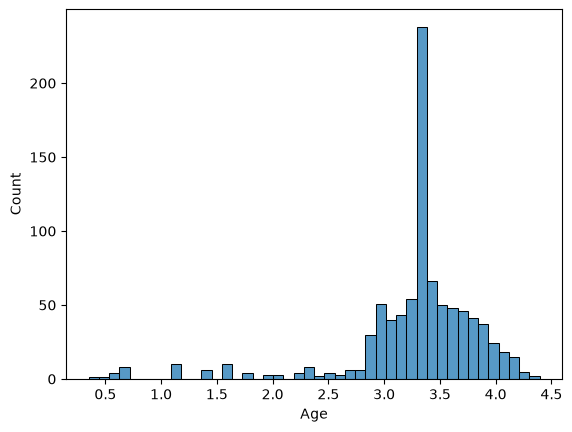

In [17]:
sns.histplot(np.log1p(df['Age']))
